# Bias audits with missing group data
**Dev Gupta and Tabassum Nadavinmani**  
**Target journal:** *Machine Learning* (Springer Nature).  
**Anchor:** Dai et al. (2025), *Assessing the risk of discriminatory bias in classification datasets*. DOI: [10.1007/s10994-025-06843-9](https://doi.org/10.1007/s10994-025-06843-9).

This self-contained notebook implements the proposal **AI_Responsibility_Proposal_Dev_Tabassum.docx** (2 November 2026). The source proposal and frozen pilot-household exclusion list are embedded as compressed provenance attachments; no separate Python module is required. The exact proposal is written into the final archive. Its dummy figures are planning illustrations and are never read as analysis data.

## Start on Kaggle
1. Create a Kaggle notebook and use **File → Import Notebook** to import this `.ipynb` (menu wording may vary). Use a **CPU** session; no GPU is needed.
2. Enable Internet to download the two public Census ZIP files automatically. Alternatively, attach them as a Kaggle input dataset; accepted filenames are `csv_pca.zip`/`csv_california.zip` and `csv_ptx.zip`/`csv_texas.zip`. Extracted `psam_p06.csv` and `psam_p48.csv` files are also supported for offline inputs.
3. Review the configuration cell. `RUN_MODE="full"` follows the proposal: all eligible non-pilot rows, 100 masks per condition, 500 household bootstrap draws for mask replicate 0. For debugging first, set `RUN_MODE="smoke"`; its smaller sample and repetitions cannot support final conclusions.
4. Run cells from top to bottom. Training and bootstrap computation may take time. Each analysis section displays **two figures and two tables**, giving 20 RQ exhibits. All displayed figures save as vector PDFs, all displayed tables as CSVs.
5. Download **`/kaggle/working/AI_Responsibility_Results_<mode>_<run-id>.zip`** using the final link or Kaggle output panel. It includes figures, tables, detailed runs, provenance and a readme. Use Kaggle's save-version function to retain the executed notebook with its visible outputs.



## Research questions
- **RQ1:** How does the missing-label proportion affect error relative to the complete-label audit?
- **RQ2:** How do random, group-dependent and outcome-dependent missingness differ?
- **RQ3:** When are complete-label disparities understated, overstated or reversed?
- **RQ4:** How do these effects differ across DP/EO metrics and LR/RF classifiers?
- **RQ5:** Are patterns consistent across CA/TX, and how does uncertainty change as support falls?

All disparities describe this analytical sample, use recorded male minus female categories, and do not establish causal discrimination, gender identity, present-day population fairness, or legal compliance. Novel visual presentation does not itself establish research novelty.

## Cell 1 — Imports and research configuration
**RQ coverage: RQ1–RQ5.** Set the prespecified experiment here, before inspecting outputs. Fixed models and a 0.5 threshold avoid selecting methods using test results. No installation is needed when Kaggle's standard scientific libraries are available. Versions are recorded rather than assumed. Full and smoke outputs are stored separately; every run gets a new directory.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import base64, zlib, hashlib, json, zipfile, shutil, platform, warnings, time
import urllib.request
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, HTML, Markdown, FileLink
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.exceptions import ConvergenceWarning

RUN_MODE = 'full'  # 'full' for proposal; 'smoke' for software debugging only
SEED = 20261102
assert RUN_MODE in ('full', 'smoke')
REPS = 100 if RUN_MODE == 'full' else 3
BOOTS = 500 if RUN_MODE == 'full' else 30
RATES = [0., .1, .3, .5, .7]
MECHANISMS = ['random', 'group', 'outcome']
ODDS_RATIO = 2.
THRESHOLD = .5
MAGNITUDE_TOLERANCE = .01  # one percentage point; descriptive, not a legal boundary
SIGN_REFERENCE_MIN = .01
NUM = ['AGEP', 'WKHP']
CAT = ['COW', 'SCHL', 'MAR', 'OCCP', 'POBP', 'RELP']
COLS = ['ST', 'SERIALNO', 'SPORDER', 'SEX', 'RAC1P', 'PINCP'] + NUM + CAT
METRICS = ['dp_gap', 'eo_gap', 'income_gap']
LABEL = {'dp_gap':'Demographic parity', 'eo_gap':'Equal opportunity', 'income_gap':'Income prevalence'}
COLORS = {'random':'#0072B2', 'group':'#D55E00', 'outcome':'#009E73', 'CA':'#0072B2', 'TX':'#CC79A7', 'LR':'#0072B2', 'RF':'#D55E00'}
BASE = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd()
INPUT_ROOT = Path('/kaggle/input')
CACHE = BASE / 'acs_download_cache'
CACHE.mkdir(exist_ok=True)
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUT = BASE / f'AI_Responsibility_Results_{RUN_MODE}_{RUN_ID}'
for name in ['figures', 'tables', 'detailed', 'provenance']:
    (OUT / name).mkdir(parents=True, exist_ok=False)
CONFIG = dict(protocol='acs-audit-kaggle-v1', journal='Machine Learning', authors=['Dev Gupta','Tabassum Nadavinmani'], mode=RUN_MODE, seed=SEED, mask_repetitions=REPS, bootstrap_repetitions=BOOTS, rates=RATES, mechanisms=MECHANISMS, missingness_odds_ratio=ODDS_RATIO, decision_threshold=THRESHOLD, magnitude_tolerance=MAGNITUDE_TOLERANCE, sign_reference_min=SIGN_REFERENCE_MIN)
VERSIONS = {'python':platform.python_version(), 'numpy':np.__version__, 'pandas':pd.__version__, 'sklearn':sklearn.__version__, 'matplotlib':matplotlib.__version__}
(OUT / 'provenance/config.json').write_text(json.dumps(CONFIG, indent=2))
(OUT / 'provenance/environment.json').write_text(json.dumps(VERSIONS, indent=2))
plt.rcParams.update({'figure.dpi':120, 'savefig.dpi':300, 'font.size':11, 'axes.titlesize':12, 'axes.labelsize':11, 'legend.fontsize':9, 'pdf.fonttype':42, 'ps.fonttype':42, 'axes.spines.top':False, 'axes.spines.right':False})
print('Mode:', RUN_MODE, '| masks:', REPS, '| bootstraps:', BOOTS)
print('Output directory:', OUT)
if RUN_MODE == 'smoke':
    print('SMOKE CHECK: reduced real-data sample; do not interpret as final evidence.')

Mode: full | masks: 100 | bootstraps: 500
Output directory: /kaggle/working/AI_Responsibility_Results_full_20261109T102333894884Z


## Cell 2 — Embedded proposal and pilot-exclusion provenance
**RQ coverage: RQ1–RQ5.** Restore the exact proposal and frozen list of earlier pilot households. Excluding these households keeps the new experiment separate from the exploratory pilot. Compressed identifiers are provenance only and contain no pilot findings. Integrity hashes make the attachments traceable. The experiment requires no external sidecar file.

In [2]:
PROPOSAL_B64 = '...'
EXCLUSIONS_B64 = '...'
proposal_payload = zlib.decompress(base64.b64decode(PROPOSAL_B64))
exclusion_payload = zlib.decompress(base64.b64decode(EXCLUSIONS_B64))
assert hashlib.sha256(proposal_payload).hexdigest() == '5debea6a84c0e63734f961a42c29e8dedd86f56814f8e38a26abd0d7bc9d9384'
assert hashlib.sha256(exclusion_payload).hexdigest() == '9057f06360f02bfe9a43a60fb7f642c85e3c53d77ca6414c4cd6f1ca8afbfddc'
(OUT / 'provenance/source_proposal.docx').write_bytes(proposal_payload)
(OUT / 'provenance/pilot_household_exclusions.json').write_bytes(exclusion_payload)
EXCLUDED = set(json.loads(exclusion_payload))
print('Source proposal restored; frozen pilot-household exclusions:', len(EXCLUDED))

Source proposal restored; frozen pilot-household exclusions: 11764


## Cell 3 — Eligibility, household splits, models and audit definitions
**RQ coverage: RQ1–RQ5.** Define the reusable research functions. Eligibility follows the proposal: age >16, income >100 and working hours >0. The target is released income >$50,000. SEX/RAC1P/income/identifiers are excluded from model predictors. Preprocessing fits on training only; household groups never cross splits.

DP is the male–female positive prediction-rate gap; EO is the male–female true-positive-rate gap. Income prevalence is a secondary descriptive gap. Empty denominators return NaN. A support flag means either group has <100 observed people or <30 observed positives. Missingness probabilities have a calibrated expected total rate and odds ratio 2 for the specified higher-risk stratum. A realized mask need not match the target rate exactly.

In [3]:
def load_state(path, state_code, exclude_households):
    """Read all person CSV members, then apply ACSIncome-style restrictions."""
    with zipfile.ZipFile(path) as archive:
        members = sorted(n for n in archive.namelist() if n.lower().endswith('.csv'))
        if not members:
            raise ValueError('No CSV in archive')
        frames = [pd.read_csv(archive.open(n), usecols=COLS,
                              dtype={'SERIALNO': str}) for n in members]
    data = pd.concat(frames, ignore_index=True)
    if not data.ST.eq(state_code).all():
        raise ValueError('Archive has unexpected state')
    if not data.SERIALNO.str.startswith('2018').all():
        raise ValueError('Expected 2018 person records')
    raw_n = len(data)
    data = data.loc[(data.AGEP > 16) & (data.PINCP > 100) & (data.WKHP > 0)].copy()
    eligible_n = len(data)
    data = data.loc[data.SEX.isin([1, 2]) & data[['ST', 'SERIALNO', 'SPORDER']].notna().all(axis=1)].copy()
    data['household'] = data.ST.astype(int).astype(str) + ':' + data.SERIALNO
    data['record_id'] = data.household + ':' + data.SPORDER.astype(int).astype(str)
    if data.record_id.duplicated().any():
        raise ValueError('Duplicate source identifiers')
    # A prior exploratory pilot exists. Exclude its whole households from main study.
    before = len(data)
    data = data.loc[~data.household.isin(exclude_households)].copy().reset_index(drop=True)
    data['y'] = (data.PINCP > 50000).astype(int)
    return data, {'raw_n': raw_n, 'eligible_n': eligible_n, 'valid_before_pilot_exclusion': before,
                  'pilot_household_rows_excluded': before - len(data), 'analysis_n': len(data),
                  'zip_sha256': hashlib.sha256(Path(path).read_bytes()).hexdigest(), 'members': members}


def split_households(data, seed):
    train, rest = next(GroupShuffleSplit(n_splits=1, test_size=.4, random_state=seed)
                       .split(data, groups=data.household))
    v, t = next(GroupShuffleSplit(n_splits=1, test_size=.5, random_state=seed + 1)
                .split(data.iloc[rest], groups=data.iloc[rest].household))
    valid, test = rest[v], rest[t]
    groups = [set(data.iloc[i].household) for i in (train, valid, test)]
    if any(groups[i] & groups[j] for i in range(3) for j in range(i + 1, 3)):
        raise AssertionError('Household leakage')
    if any(data.iloc[i].y.nunique() != 2 for i in (train, valid, test)):
        raise ValueError('Each split must contain both outcome classes')
    return train, valid, test


def make_models(seed):
    prep = ColumnTransformer([
        ('numeric', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), NUM),
        ('categorical', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                     OneHotEncoder(handle_unknown='ignore')), CAT)])
    # Hyperparameters fixed in advance; validation is for diagnostics, not test tuning.
    return {
        'LR': make_pipeline(clone(prep), LogisticRegression(C=1, solver='liblinear',
                                                           max_iter=3000, random_state=seed)),
        'RF': make_pipeline(clone(prep), RandomForestClassifier(n_estimators=200,
                         min_samples_leaf=20, max_features='sqrt', n_jobs=-1, random_state=seed))}


def audit(y, pred, group, keep=None, weights=None):
    """Unweighted sample disparities, male minus female; NaN for empty cells."""
    keep = np.ones(len(y), dtype=bool) if keep is None else keep
    weights = np.ones(len(y)) if weights is None else weights
    def mean(values, subset):
        sel = subset & keep
        return float(np.average(values[sel], weights=weights[sel])) if weights[sel].sum() > 0 else np.nan
    male, female = group == 1, group == 2
    out = {'income_gap': mean(y, male) - mean(y, female),
           'dp_gap': mean(pred, male) - mean(pred, female),
           'eo_gap': mean(pred, male & (y == 1)) - mean(pred, female & (y == 1))}
    counts = [int((keep & g).sum()) for g in (male, female)]
    positives = [int((keep & g & (y == 1)).sum()) for g in (male, female)]
    out.update(n_male=counts[0], n_female=counts[1], positive_male=positives[0], positive_female=positives[1],
               low_support=min(counts) < 100 or min(positives) < 30)
    return out


def missing_probabilities(group, y, rate, mechanism):
    """Calibrated expected rate. Group/outcome mechanisms use odds ratio 2."""
    if not 0 <= rate < 1:
        raise ValueError('Missing fraction must lie in [0,1)')
    if rate == 0:
        return np.zeros(len(y))
    z = {'random': np.zeros(len(y)), 'group': (group == 2).astype(float),
         'outcome': (y == 1).astype(float)}[mechanism]
    lo, hi = -40., 40.
    for _ in range(100):
        alpha = (lo + hi) / 2
        q = 1 / (1 + np.exp(-(alpha + np.log(ODDS_RATIO) * z)))
        if q.mean() < rate:
            lo = alpha
        else:
            hi = alpha
    q = 1 / (1 + np.exp(-((lo + hi) / 2 + np.log(ODDS_RATIO) * z)))
    if not np.isclose(q.mean(), rate, atol=1e-9):
        raise AssertionError('Failed probability calibration')
    return q

## Cell 4 — Public data acquisition and input validation
**RQ coverage: RQ1–RQ5.** Locate attached Kaggle input archives first, then use a cached copy, then try direct public downloads. ZIP structure, state, year, required columns and identifiers are validated. Raw source archives are not included in the results ZIP. A failed download gives an explicit offline-upload instruction instead of switching datasets.

Sources: [California](https://www2.census.gov/programs-surveys/acs/data/pums/2018/1-Year/csv_pca.zip), [Texas](https://www2.census.gov/programs-surveys/acs/data/pums/2018/1-Year/csv_ptx.zip), [dictionary](https://www2.census.gov/programs-surveys/acs/tech_docs/pums/data_dict/PUMS_Data_Dictionary_2018.pdf), [Folktables](https://github.com/socialfoundations/folktables). Census public-use data and Folktables' MIT software license have separate terms. This is an unweighted analytical-sample study.

In [4]:
SOURCES = {'CA':(6, 'csv_pca.zip', 'csv_california.zip'), 'TX':(48, 'csv_ptx.zip', 'csv_texas.zip')}
BASE_URL = 'https://www2.census.gov/programs-surveys/acs/data/pums/2018/1-Year/'
def valid_archive(path):
    try:
        with zipfile.ZipFile(path) as z:
            return any(n.lower().endswith('.csv') for n in z.namelist()) and z.testzip() is None
    except (OSError, zipfile.BadZipFile):
        return False

def locate_archive(names):
    if INPUT_ROOT.exists():
        hits = sorted(p for p in INPUT_ROOT.rglob('*.zip') if p.name in names)
        for p in hits:
            if valid_archive(p):
                return p
        # Kaggle may unpack uploaded ZIPs; accept the official person CSV basename.
        csv_name = 'psam_p06.csv' if names[0]=='csv_pca.zip' else 'psam_p48.csv'
        csv_hits = sorted(INPUT_ROOT.rglob(csv_name))
        if csv_hits:
            repacked = CACHE / ('repacked_' + names[0])
            with zipfile.ZipFile(repacked,'w',compression=zipfile.ZIP_STORED) as z:
                z.write(csv_hits[0],csv_name)
            return repacked
    path = CACHE / names[0]
    if path.exists() and valid_archive(path):
        return path
    url = BASE_URL + names[0]
    error = None
    for attempt in range(2):
        partial = path.with_suffix('.part')
        try:
            request = urllib.request.Request(url, headers={'User-Agent':'ACS-Fairness-Audit-Research/1.0'})
            with urllib.request.urlopen(request, timeout=120) as response, partial.open('wb') as f:
                shutil.copyfileobj(response, f)
            if not valid_archive(partial):
                raise ValueError('Downloaded content is not a valid Census CSV ZIP')
            partial.replace(path)
            return path
        except Exception as exc:
            partial.unlink(missing_ok=True)
            error = exc
    raise RuntimeError(f'Could not download {url}. Enable Internet, or attach the official ZIP as a Kaggle input dataset using filename {names[0]}. Last error: {error}')

DATA, SPLITS, INPUT_MANIFEST = {}, {}, {}
flow_rows = []
for i, (state, (fips, canonical, alias)) in enumerate(SOURCES.items()):
    path = locate_archive((canonical, alias))
    data, info = load_state(path, fips, EXCLUDED)
    full_n = len(data)
    if RUN_MODE == 'smoke':
        # Select whole households for a small software check; full mode uses all rows.
        households = data.household.drop_duplicates().sample(frac=1, random_state=SEED)
        selected = set(households.iloc[:min(3500, len(households))])
        data = data.loc[data.household.isin(selected)].reset_index(drop=True)
    train, validation, test = split_households(data, SEED + 10*i)
    split_labels = np.full(len(data), 'train', dtype=object)
    split_labels[validation], split_labels[test] = 'validation', 'test'
    data[['record_id','household']].assign(split=split_labels).to_csv(OUT / f'detailed/{state}_sampling_frame.csv', index=False)
    info.update(source_url=BASE_URL+canonical, local_archive_name=path.name, input_form='repacked extracted CSV' if path.name.startswith('repacked_') else 'source ZIP', eligible_nonpilot_n=full_n, used_n=len(data), train_n=len(train), validation_n=len(validation), test_n=len(test))
    INPUT_MANIFEST[state] = info
    DATA[state], SPLITS[state] = data, (train, validation, test)
    flow_rows.append({'state':state, **{k:v for k,v in info.items() if k.endswith('_n')}})
(OUT / 'provenance/input_manifest.json').write_text(json.dumps(INPUT_MANIFEST, indent=2))
print('Validated both states and created disjoint household splits.')

Validated both states and created disjoint household splits.


## Cell 5 — Scientific display and export helpers
**RQ coverage: RQ1–RQ5.** All table displays pass through `show_table`, which saves the full data as CSV and displays it in a scrollable, labeled HTML table. All figures pass through `show_figure`, which saves a vector PDF and displays the same figure inline. Legends, units, captions and color choices are explicit. No figure's shape or significance is forced to match the proposal's dummy illustrations. The output index links each artifact to its research question.

In [5]:
ARTIFACTS = []
def show_table(frame, name, caption, rq='Methods'):
    frame = frame.reset_index(drop=True)
    path = OUT / 'tables' / (name + '.csv')
    frame.to_csv(path, index=False)
    ARTIFACTS.append({'rq':rq,'kind':'table','file':str(path.relative_to(OUT)),'caption':caption})
    display(Markdown('**'+caption+'**'))
    html = frame.to_html(index=False, float_format=lambda x:f'{x:.4f}', na_rep='undefined', escape=True)
    display(HTML('<div style="max-height:550px;overflow:auto;border:1px solid #ddd">'+html+'</div>'))

def show_figure(fig, name, caption, rq):
    if RUN_MODE == 'smoke':
        fig.text(.99,.005,'SMOKE CHECK — exploratory software validation only',ha='right',fontsize=8,color='#B2182B')
    path = OUT / 'figures' / (name + '.pdf')
    fig.savefig(path, bbox_inches='tight', format='pdf')
    ARTIFACTS.append({'rq':rq,'kind':'figure','file':str(path.relative_to(OUT)),'caption':caption})
    plt.show()
    plt.close(fig)
    display(Markdown('**'+caption+'**'))

def decorate(ax, xlabel=None, ylabel=None, title=None):
    if xlabel:ax.set_xlabel(xlabel)
    if ylabel:ax.set_ylabel(ylabel)
    if title:ax.set_title(title)
    ax.grid(axis='y', alpha=.22)
    ax.set_axisbelow(True)

flow = pd.DataFrame(flow_rows)
show_table(flow, 'M01_inclusion_flow', 'M1. Input, eligibility, pilot-exclusion and split counts; smoke sampling is identified separately.')
dictionary = pd.DataFrame([
('AGEP','Age in years','Numeric predictor; >16'),('WKHP','Weekly work hours','Numeric predictor; >0'),
('PINCP','Released person income','Eligibility >100; target >50000; never predictor'),
('SEX','Recorded sex: 1 male, 2 female','Audit only; not gender identity'),
('RAC1P','Recorded race category','Reserved for future audits; never predictor'),
('COW/SCHL/MAR/OCCP/POBP/RELP','Worker class/education/marital status/occupation/birthplace/relationship','Categorical predictors'),
('ST/SERIALNO/SPORDER','State/household/person order','Traceability and grouped split only'),
('DP/EO gaps','Male minus female rates','Proportions in detailed files; pp in presentation tables'),
('NaN','Undefined estimate or ineligible reversal','Never interpreted as zero')],columns=['field','meaning','role'])
show_table(dictionary, 'M02_data_dictionary', 'M2. Core data dictionary and measurement units.')

**M1. Input, eligibility, pilot-exclusion and split counts; smoke sampling is identified separately.**

state,raw_n,eligible_n,analysis_n,eligible_nonpilot_n,used_n,train_n,validation_n,test_n
CA,378817,195665,182751,182751,182751,109445,36585,36721
TX,268100,135924,124200,124200,124200,74601,24838,24761


**M2. Core data dictionary and measurement units.**

field,meaning,role
AGEP,Age in years,Numeric predictor; >16
WKHP,Weekly work hours,Numeric predictor; >0
PINCP,Released person income,Eligibility >100; target >50000; never predictor
SEX,"Recorded sex: 1 male, 2 female",Audit only; not gender identity
RAC1P,Recorded race category,Reserved for future audits; never predictor
COW/SCHL/MAR/OCCP/POBP/RELP,Worker class/education/marital status/occupation/birthplace/relationship,Categorical predictors
ST/SERIALNO/SPORDER,State/household/person order,Traceability and grouped split only
DP/EO gaps,Male minus female rates,Proportions in detailed files; pp in presentation tables
NaN,Undefined estimate or ineligible reversal,Never interpreted as zero


## Cell 6 — Baseline fitting and frozen test predictions
**RQ coverage: RQ4 directly; reference predictions for RQ1–RQ5.** Fit both classifiers on training rows only. Validation and test performance are reported separately. Hyperparameters and threshold remain fixed, so the validation set serves diagnostics, not tuning. Training warnings that indicate nonconvergence stop the analysis. Save the exact frozen test outputs and split identifiers. Models are never retrained during masking.

In [6]:
TEST, performance_rows = {}, []
for state, data in DATA.items():
    train, valid, test = SPLITS[state]
    frozen = {}
    for model_name, pipeline in make_models(SEED).items():
        print('Training:', state, model_name, flush=True)
        with warnings.catch_warnings():
            warnings.simplefilter('error', ConvergenceWarning)
            pipeline.fit(data.iloc[train][NUM+CAT], data.y.iloc[train])
        for split_name, indices in [('validation', valid), ('test', test)]:
            prob = pipeline.predict_proba(data.iloc[indices][NUM+CAT])[:,1]
            pred = (prob >= THRESHOLD).astype(int)
            performance_rows.append({'state':state,'model':model_name,'split':split_name,'n':len(indices),'accuracy':accuracy_score(data.y.iloc[indices],pred),'auc':roc_auc_score(data.y.iloc[indices],prob)})
            if split_name == 'test':
                frozen[model_name] = pred
                pd.DataFrame({'record_id':data.record_id.iloc[test].to_numpy(),'y':data.y.iloc[test].to_numpy(),'SEX':data.SEX.iloc[test].to_numpy(),'probability':prob,'prediction':pred}).to_csv(OUT / f'detailed/{state}_{model_name}_frozen_predictions.csv', index=False)
        del pipeline
    TEST[state] = dict(y=data.y.iloc[test].to_numpy(),group=data.SEX.iloc[test].to_numpy(),household=data.household.iloc[test].to_numpy(),predictions=frozen)
PERFORMANCE = pd.DataFrame(performance_rows)
PERFORMANCE.to_csv(OUT / 'detailed/predictive_performance.csv', index=False)
REFERENCE = {(s,m):audit(t['y'],pred,t['group']) for s,t in TEST.items() for m,pred in t['predictions'].items()}
reference_table = pd.DataFrame([{'state':s,'model':m,**vals} for (s,m),vals in REFERENCE.items()])
show_table(reference_table, 'M03_complete_label_reference', 'M3. Complete-label sample reference gaps (proportions), denominators and support flags. This is a sample reference, not ethical ground truth.')

Training: CA LR
Training: CA RF
Training: TX LR
Training: TX RF


**M3. Complete-label sample reference gaps (proportions), denominators and support flags. This is a sample reference, not ethical ground truth.**

state,model,income_gap,dp_gap,eo_gap,n_male,n_female,positive_male,positive_female,low_support
CA,LR,0.1238,0.0826,0.0013,19349,17372,9184,6095,False
CA,RF,0.1238,0.0474,-0.0310,19349,17372,9184,6095,False
TX,LR,0.1595,0.1224,0.0377,13236,11525,5835,3242,False
TX,RF,0.1595,0.0642,-0.0272,13236,11525,5835,3242,False


## Cell 7 — Conditional household-bootstrap estimator
**RQ coverage: RQ5; uncertainty for RQ1–RQ4.** Resample held-out households with replacement and retain all members of each sampled household. Aggregate sufficient statistics by household first to reduce computation while preserving the estimator. Use 500 draws in full mode for the prespecified mask replicate 0 in each condition. Require ≥95% finite bootstrap estimates before reporting percentile endpoints.

These intervals condition on the fitted classifier and current missing-label mask. They exclude training uncertainty and the distribution of all possible masks; they are not ACS design-based population intervals. The spread across the 100 masks is reported separately. Interval inclusion of the complete-label sample reference is a diagnostic, not a population coverage guarantee.

In [7]:
def safe_divide(num, den):
    return np.divide(num, den, out=np.full(np.broadcast(num,den).shape,np.nan,dtype=float), where=den>0)

def cluster_intervals(y, pred, group, households, keep, repetitions, seed):
    _, inv = np.unique(households, return_inverse=True)
    n = int(inv.max()+1)
    male, female = keep & (group==1), keep & (group==2)
    columns = [male, female, male*y, female*y, male*pred, female*pred, male*y*pred, female*y*pred]
    sufficient = np.column_stack([np.bincount(inv, weights=c.astype(float), minlength=n) for c in columns])
    rng = np.random.default_rng(seed)
    blocks = []
    for start in range(0,repetitions,25):
        weights = rng.multinomial(n, np.full(n,1/n), size=min(25,repetitions-start))
        totals = weights @ sufficient
        income = safe_divide(totals[:,2],totals[:,0])-safe_divide(totals[:,3],totals[:,1])
        dp = safe_divide(totals[:,4],totals[:,0])-safe_divide(totals[:,5],totals[:,1])
        eo = safe_divide(totals[:,6],totals[:,2])-safe_divide(totals[:,7],totals[:,3])
        blocks.append(np.column_stack([dp,eo,income]))
    draws = np.vstack(blocks)
    result = {}
    for j,metric in enumerate(METRICS):
        vals = draws[:,j]; finite = vals[np.isfinite(vals)]
        lo,hi = np.quantile(finite,[.025,.975]) if len(finite)>=.95*repetitions else (np.nan,np.nan)
        result[metric] = dict(lo=float(lo),hi=float(hi),valid_boot=len(finite))
    return result

# Deterministic internal sanity checks, using tiny synthetic arrays only.
_yy=np.array([1,0,1,0]); _aa=np.array([1,1,2,2]); _pp=np.array([1,1,1,0])
assert np.isclose(audit(_yy,_pp,_aa)['dp_gap'],.5)
assert np.isclose(audit(_yy,_pp,_aa)['eo_gap'],0.)
assert np.isnan(audit(_yy,_pp,_aa,keep=_aa==1)['dp_gap'])
for _mechanism in MECHANISMS:
    assert np.all(missing_probabilities(_aa,_yy,0.,_mechanism)==0)
    assert np.isclose(missing_probabilities(_aa,_yy,.7,_mechanism).mean(),.7)
print('Audit identities and missingness calibration sanity checks passed.')

Audit identities and missingness calibration sanity checks passed.


## Cell 8 — Paired missing-label experiments and conditional intervals
**RQ coverage: RQ1–RQ5.** For each state, mechanism and rate, draw 100 masks, reuse each mask across both models, and audit only observed labels. Use independent seed streams across states, mechanisms, rates and replicates; paired model comparisons share the identical mask. Reference labels are used only to simulate missingness and evaluate audit error, never as model predictors.

Save per-run signed error, absolute error, magnitude change, under/overstatement (±1 pp tolerance), sign reversal (only |reference|≥1 pp), realized missingness and support. Bootstrap only replicate 0. No undefined or low-support run is silently discarded: denominators and flags accompany summaries. The cell prints progress and checkpoints detailed CSVs after each state. The zero-missingness error must be exactly zero.

In [8]:
run_rows, ci_rows, mechanism_rows = [], [], []
started = time.time()
for si,(state,t) in enumerate(TEST.items()):
    y,group,households=t['y'],t['group'],t['household']
    for mi,mechanism in enumerate(MECHANISMS):
        for ri,rate in enumerate(RATES):
            q=missing_probabilities(group,y,rate,mechanism)
            risk = np.zeros(len(y),dtype=bool) if mechanism=='random' else group==2 if mechanism=='group' else y==1
            mechanism_rows.append({'state':state,'mechanism':mechanism,'rate':rate,'expected_missing':q.mean(),'low_risk_probability':q[~risk].mean() if (~risk).any() else np.nan,'high_risk_probability':q[risk].mean() if risk.any() else np.nan,'high_risk_fraction':risk.mean()})
            for rep in range(REPS):
                seed_sequence=np.random.SeedSequence([SEED,si,mi,ri,rep])
                keep=np.random.default_rng(seed_sequence).random(len(y))>=q
                for model,pred in t['predictions'].items():
                    ref=REFERENCE[state,model]
                    observed=audit(y,pred,group,keep)
                    common={'state':state,'model':model,'mechanism':mechanism,'rate':rate,'rep':rep,'realized_missing':1-keep.mean(),'observed_n':int(keep.sum()),'n_male':observed['n_male'],'n_female':observed['n_female'],'positive_male':observed['positive_male'],'positive_female':observed['positive_female'],'low_support':observed['low_support']}
                    intervals=cluster_intervals(y,pred,group,households,keep,BOOTS,SEED+10000*si+1000*mi+10*ri) if rep==0 else None
                    for metric in METRICS:
                        value,reference=observed[metric],ref[metric]
                        error=value-reference
                        magnitude_change=abs(value)-abs(reference)
                        finite=np.isfinite(value) and np.isfinite(reference)
                        reversal=float(value*reference<0) if finite and abs(reference)>=SIGN_REFERENCE_MIN else np.nan
                        row={**common,'metric':metric,'estimate':value,'reference':reference,'error':error,'abs_error':abs(error),'magnitude_change':magnitude_change,'reversed':reversal,'under':float(magnitude_change < -MAGNITUDE_TOLERANCE) if finite else np.nan,'over':float(magnitude_change > MAGNITUDE_TOLERANCE) if finite else np.nan,'within':float(abs(magnitude_change)<=MAGNITUDE_TOLERANCE) if finite else np.nan}
                        if rate==0 and finite:
                            assert abs(error)<1e-12, 'Zero missingness must reproduce complete reference'
                        run_rows.append(row)
                        if intervals is not None:
                            ci=intervals[metric]
                            ci_rows.append({**row,**ci,'width':ci['hi']-ci['lo'],'reference_in_interval':float(ci['lo']<=reference<=ci['hi']) if np.isfinite(ci['lo']+ci['hi']) else np.nan})
            print(f'{state} | {mechanism:7s} | expected missing={rate:.0%} complete',flush=True)
    pd.DataFrame(run_rows).to_csv(OUT/'detailed/audit_runs_checkpoint.csv',index=False)
    pd.DataFrame(ci_rows).to_csv(OUT/'detailed/conditional_intervals_checkpoint.csv',index=False)
RUNS=pd.DataFrame(run_rows); CI=pd.DataFrame(ci_rows); MECH=pd.DataFrame(mechanism_rows)
RUNS.to_csv(OUT/'detailed/audit_runs.csv',index=False)
CI.to_csv(OUT/'detailed/conditional_intervals.csv',index=False)
MECH.to_csv(OUT/'detailed/missingness_probabilities.csv',index=False)
print('Experiment finished in',round((time.time()-started)/60,1),'minutes.')

CA | random  | expected missing=0% complete
CA | random  | expected missing=10% complete
CA | random  | expected missing=30% complete
CA | random  | expected missing=50% complete
CA | random  | expected missing=70% complete
CA | group   | expected missing=0% complete
CA | group   | expected missing=10% complete
CA | group   | expected missing=30% complete
CA | group   | expected missing=50% complete
CA | group   | expected missing=70% complete
CA | outcome | expected missing=0% complete
CA | outcome | expected missing=10% complete
CA | outcome | expected missing=30% complete
CA | outcome | expected missing=50% complete
CA | outcome | expected missing=70% complete
TX | random  | expected missing=0% complete
TX | random  | expected missing=10% complete
TX | random  | expected missing=30% complete
TX | random  | expected missing=50% complete
TX | random  | expected missing=70% complete
TX | group   | expected missing=0% complete
TX | group   | expected missing=10% complete
TX | group   | 

## Cell 9 — Analysis summaries, Monte Carlo precision and event denominators
**RQ coverage: RQ1–RQ5.** Aggregate the repeated-mask experiments within each state/model/mechanism/rate/metric. MAE and signed bias are in proportions internally; display tables explicitly convert to percentage points. The Monte Carlo SE describes precision of the average over simulated masks, not statistical uncertainty about population disparities. Event SE uses the actual eligible replicate count; zero observed reversals does not prove zero risk. At zero missingness, duplicate masks are deterministic controls.

In [14]:
KEYS=['state','model','mechanism','rate','metric']
SUMMARY=RUNS.groupby(KEYS,as_index=False).agg(mean_error=('error','mean'),mae=('abs_error','mean'),mask_sd=('error','std'),abs_sd=('abs_error','std'),valid_n=('error','count'),under_rate=('under','mean'),over_rate=('over','mean'),within_rate=('within','mean'),reversal_rate=('reversed','mean'),reversal_eligible_n=('reversed','count'),low_support_fraction=('low_support','mean'))
SUMMARY['mae_mcse']=SUMMARY.abs_sd/np.sqrt(SUMMARY.valid_n)
SUMMARY['bias_mcse']=SUMMARY.mask_sd/np.sqrt(SUMMARY.valid_n)
SUMMARY['reversal_mcse']=np.sqrt(SUMMARY.reversal_rate*(1-SUMMARY.reversal_rate)/SUMMARY.reversal_eligible_n.replace(0,np.nan))
SUMMARY.to_csv(OUT/'detailed/audit_summary.csv',index=False)
SUPPORT=RUNS.drop_duplicates(['state','mechanism','rate','rep'])
assert RUNS.loc[RUNS.rate.eq(0),'abs_error'].dropna().max()<1e-12
assert (RUNS.low_support | (RUNS.n_male.ge(100)&RUNS.n_female.ge(100)&RUNS.positive_male.ge(30)&RUNS.positive_female.ge(30))).all()

def pp_table(frame,columns):
    result=frame.copy()
    for c in columns:
        result[c+'_pp']=100*result[c]
    return result.drop(columns=columns)

def subset(frame,**conditions):
    mask=np.ones(len(frame),dtype=bool)
    for col,value in conditions.items():mask &= frame[col].eq(value).to_numpy()
    return frame.loc[mask].copy()
print('Summary conditions:',len(SUMMARY),'| complete-label control passed.')

Summary conditions: 180 | complete-label control passed.


## Cell 10 — RQ1: error and support versus missing-label rate
**Research question:** How does the missing proportion affect audit-estimation error?

**Outputs:** F1 plots DP/EO MAE for CA–LR under random masking, with approximate 95% Monte Carlo intervals for mean absolute error (not population confidence intervals). F2 shows average remaining records for both states under random masking. T1 reports the corresponding CA–LR errors and valid denominators; T2 reports state-specific support. Other mechanisms and classifiers are retained in the detailed summary and explored below. Increasing error is a possibility, not an imposed result.

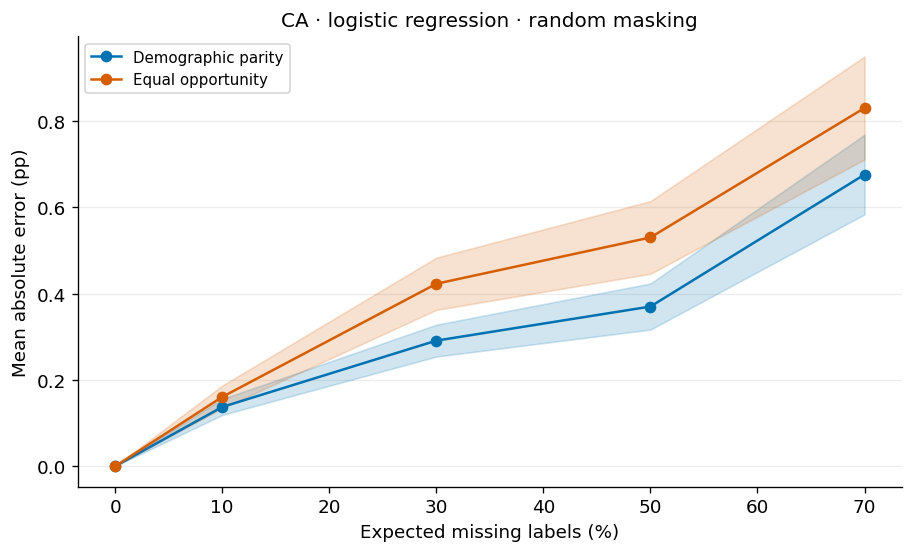

**RQ1 F1. Audit MAE versus missingness. Shading: approximate 95% Monte Carlo intervals for the mean over masks.**

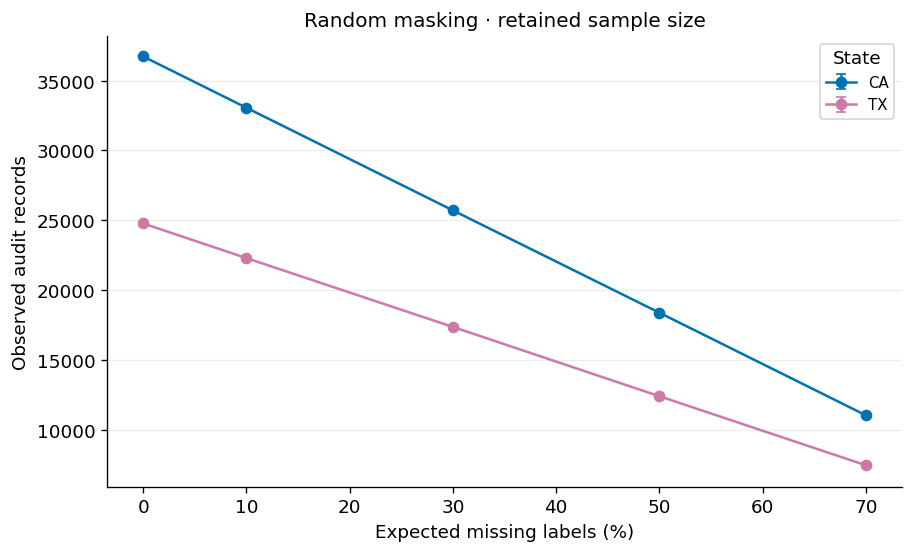

**RQ1 F2. Average retained records; error bars show SD across masks, not sampling uncertainty.**

**RQ1 T1. CA–LR random masking: signed bias, MAE and Monte Carlo SE in pp; rate is a fraction.**

rate,metric,valid_n,mean_error_pp,mae_pp,mae_mcse_pp
0.0000,dp_gap,100,0.0000,0.0000,0.0000
0.0000,eo_gap,100,0.0000,0.0000,0.0000
0.0000,income_gap,100,0.0000,0.0000,0.0000
0.1000,dp_gap,100,0.0016,0.1373,0.0094
0.1000,eo_gap,100,-0.0145,0.1606,0.0134
0.1000,income_gap,100,0.0188,0.1564,0.0111
0.3000,dp_gap,100,0.0062,0.2912,0.0189
0.3000,eo_gap,100,-0.0723,0.4231,0.0309
0.3000,income_gap,100,0.0684,0.2900,0.0188
0.5000,dp_gap,100,0.0057,0.3703,0.0273


**RQ1 T2. Random masking: mean sample size and minimum observed support across masks.**

state,rate,mean_observed_n,minimum_male_n,minimum_female_n,minimum_male_positives,minimum_female_positives
CA,0.0000,36721.0000,19349,17372,9184,6095
CA,0.1000,33047.5200,17326,15540,8187,5432
CA,0.3000,25696.8000,13377,12044,6347,4149
CA,0.5000,18366.2500,9532,8473,4474,2969
CA,0.7000,11020.5300,5677,5073,2646,1727
TX,0.0000,24761.0000,13236,11525,5835,3242
TX,0.1000,22279.0700,11821,10243,5204,2873
TX,0.3000,17348.6000,9145,7956,4011,2216
TX,0.5000,12384.8300,6470,5605,2833,1549
TX,0.7000,7441.1200,3855,3324,1663,917


In [15]:
s=subset(SUMMARY,state='CA',model='LR',mechanism='random')
fig,ax=plt.subplots(figsize=(7.5,4.5),layout='constrained')
for metric,color in [('dp_gap','#0072B2'),('eo_gap','#D55E00')]:
    g=subset(s,metric=metric).sort_values('rate');x=100*g.rate.to_numpy();mean=100*g.mae.to_numpy();band=196*g.mae_mcse.to_numpy()
    ax.plot(x,mean,'o-',label=LABEL[metric],color=color)
    ax.fill_between(x,np.maximum(0,mean-band),mean+band,color=color,alpha=.18)
decorate(ax,'Expected missing labels (%)','Mean absolute error (pp)','CA · logistic regression · random masking');ax.legend()
show_figure(fig,'RQ1_F1_error_vs_missingness','RQ1 F1. Audit MAE versus missingness. Shading: approximate 95% Monte Carlo intervals for the mean over masks.', 'RQ1')
fig,ax=plt.subplots(figsize=(7.5,4.5),layout='constrained')
for state in SOURCES:
    g=subset(SUPPORT,state=state,mechanism='random').groupby('rate').observed_n.agg(['mean','std']).reset_index()
    ax.errorbar(100*g.rate,g['mean'],yerr=g['std'],fmt='o-',capsize=3,label=state,color=COLORS[state])
decorate(ax,'Expected missing labels (%)','Observed audit records','Random masking · retained sample size');ax.legend(title='State')
show_figure(fig,'RQ1_F2_support_vs_missingness','RQ1 F2. Average retained records; error bars show SD across masks, not sampling uncertainty.', 'RQ1')
t=s[['rate','metric','mean_error','mae','mae_mcse','valid_n']]
show_table(pp_table(t,['mean_error','mae','mae_mcse']),'RQ1_T1_error_by_rate','RQ1 T1. CA–LR random masking: signed bias, MAE and Monte Carlo SE in pp; rate is a fraction.','RQ1')
t=subset(SUPPORT,mechanism='random').groupby(['state','rate'],as_index=False).agg(mean_observed_n=('observed_n','mean'),minimum_male_n=('n_male','min'),minimum_female_n=('n_female','min'),minimum_male_positives=('positive_male','min'),minimum_female_positives=('positive_female','min'))
show_table(t,'RQ1_T2_support_by_rate','RQ1 T2. Random masking: mean sample size and minimum observed support across masks.','RQ1')

## Cell 11 — RQ2: mechanisms and calibrated missingness probabilities
**Research question:** How do random, group-dependent and outcome-dependent mechanisms differ?

**Outputs:** F3 compares mean signed errors across metrics for CA–LR at 50% expected missingness. F4 shows the EO-error distribution across masks under each mechanism. T3 expands the numerical comparison to both states/models; T4 records the actual calibrated probabilities and the high-risk fraction. Group-only missingness can reduce precision without systematic rate bias. Outcome-only missingness need not bias TPR; report null effects without treating them as failures. Degenerate distributions use points instead of a misleading violin.

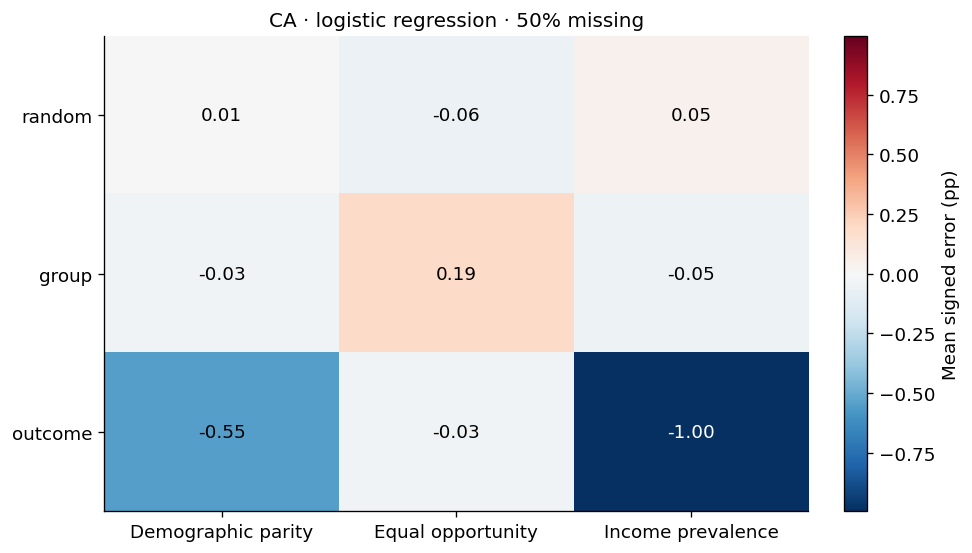

**RQ2 F3. Signed error by missingness mechanism and audit metric; diverging colors are centered at zero.**

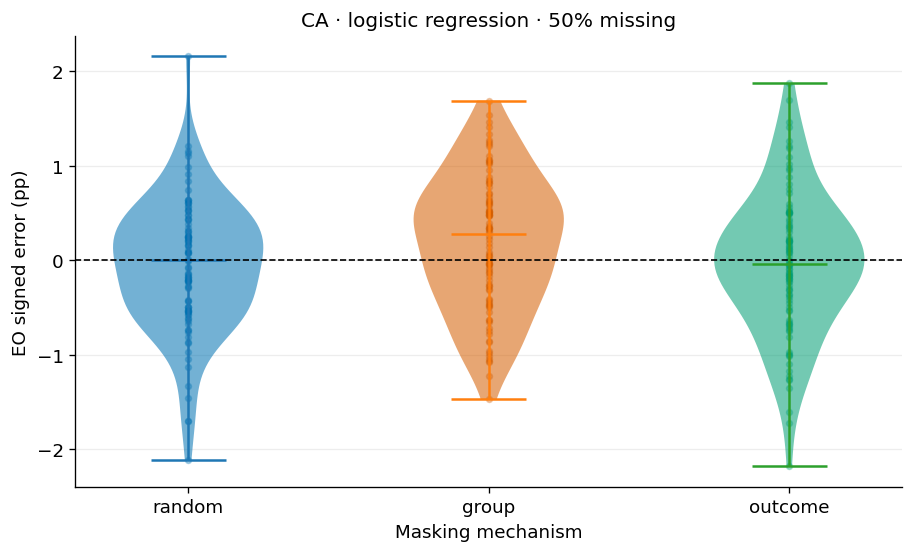

**RQ2 F4. EO error distribution across masks; points are individual mask runs.**

**RQ2 T3. Mechanism comparison at 50% expected missingness; audit errors and mask SD in pp.**

state,model,mechanism,metric,valid_n,mean_error_pp,mae_pp,mask_sd_pp
CA,LR,group,dp_gap,100,-0.0314,0.4114,0.5039
CA,LR,group,eo_gap,100,0.1870,0.6061,0.7093
CA,LR,group,income_gap,100,-0.0494,0.4560,0.5775
CA,LR,outcome,dp_gap,100,-0.5488,0.6109,0.4879
CA,LR,outcome,eo_gap,100,-0.0331,0.5741,0.7500
CA,LR,outcome,income_gap,100,-0.9951,1.0033,0.5012
CA,LR,random,dp_gap,100,0.0057,0.3703,0.4613
CA,LR,random,eo_gap,100,-0.0554,0.5304,0.6826
CA,LR,random,income_gap,100,0.0455,0.3598,0.4494
CA,RF,group,dp_gap,100,-0.0490,0.4183,0.5287


**RQ2 T4. Calibrated probabilities and risk-stratum mix. Random masking has no distinct high-risk stratum (undefined).**

state,mechanism,rate,expected_missing,low_risk_probability,high_risk_probability,high_risk_fraction
CA,random,0.5000,0.5000,0.5000,undefined,0.0000
CA,group,0.5000,0.5000,0.4188,0.5904,0.4731
CA,outcome,0.5000,0.5000,0.4287,0.6001,0.4161
TX,random,0.5000,0.5000,0.5000,undefined,0.0000
TX,group,0.5000,0.5000,0.4202,0.5917,0.4654
TX,outcome,0.5000,0.5000,0.4372,0.6084,0.3666


In [16]:
s=subset(SUMMARY,state='CA',model='LR',rate=.5)
pivot=s.pivot(index='mechanism',columns='metric',values='mean_error').reindex(index=MECHANISMS,columns=METRICS)*100
fig,ax=plt.subplots(figsize=(8,4.5),layout='constrained')
vmax=max(float(np.nanmax(np.abs(pivot.to_numpy()))),.1)
im=ax.imshow(pivot.to_numpy(),cmap='RdBu_r',vmin=-vmax,vmax=vmax,aspect='auto')
ax.set_xticks(range(3),[LABEL[m] for m in METRICS]);ax.set_yticks(range(3),MECHANISMS)
for i in range(3):
    for j in range(3):
        v=pivot.iloc[i,j];ax.text(j,i,f'{v:.2f}' if np.isfinite(v) else 'undefined',ha='center',va='center',color='white' if abs(v)>.6*vmax else 'black')
ax.set_title('CA · logistic regression · 50% missing');fig.colorbar(im,ax=ax,label='Mean signed error (pp)')
show_figure(fig,'RQ2_F3_mechanism_bias','RQ2 F3. Signed error by missingness mechanism and audit metric; diverging colors are centered at zero.','RQ2')
fig,ax=plt.subplots(figsize=(7.5,4.5),layout='constrained')
for i,mechanism in enumerate(MECHANISMS,1):
    vals=100*subset(RUNS,state='CA',model='LR',rate=.5,metric='eo_gap',mechanism=mechanism).error.dropna().to_numpy()
    if len(vals)>1 and np.ptp(vals)>1e-12:
        violin=ax.violinplot([vals],positions=[i],showmedians=True)
        for body in violin['bodies']:body.set_facecolor(COLORS[mechanism]);body.set_alpha(.55)
    ax.scatter(np.full(len(vals),i),vals,s=12,alpha=.3,color=COLORS[mechanism])
ax.axhline(0,color='black',lw=1,ls='--');ax.set_xticks([1,2,3],MECHANISMS)
decorate(ax,'Masking mechanism','EO signed error (pp)','CA · logistic regression · 50% missing')
show_figure(fig,'RQ2_F4_eo_error_distributions','RQ2 F4. EO error distribution across masks; points are individual mask runs.','RQ2')
t=subset(SUMMARY,rate=.5)[['state','model','mechanism','metric','mean_error','mae','mask_sd','valid_n']]
show_table(pp_table(t,['mean_error','mae','mask_sd']),'RQ2_T3_mechanism_comparison','RQ2 T3. Mechanism comparison at 50% expected missingness; audit errors and mask SD in pp.','RQ2')
show_table(subset(MECH,rate=.5),'RQ2_T4_missingness_probabilities','RQ2 T4. Calibrated probabilities and risk-stratum mix. Random masking has no distinct high-risk stratum (undefined).','RQ2')

## Cell 12 — RQ3: understatement, overstatement and sign reversals
**Research question:** When do incomplete audits give misleading magnitude or sign conclusions?

**Outputs:** F5 partitions CA–LR DP masks into understatement, overstatement or within ±1 pp. F6 shows DP reversal frequencies across state/model/mechanism conditions. T5 gives event rates and valid counts at 50% missingness; T6 gives reversal eligibility, frequencies and Monte Carlo SE. Reversals are undefined when the complete reference magnitude is below 1 pp. The tolerance is a descriptive choice, not a legal fairness threshold. Empty cells remain visibly undefined.

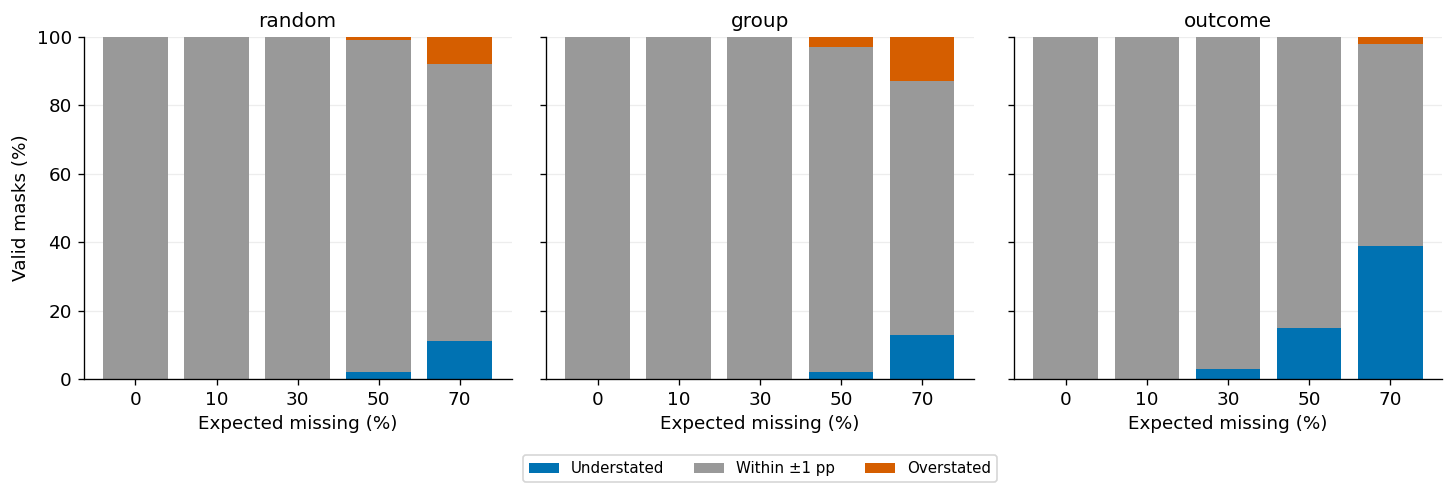

**RQ3 F5. CA–LR DP magnitude classifications. All categories compare absolute disparity magnitudes with a ±1 pp tolerance.**

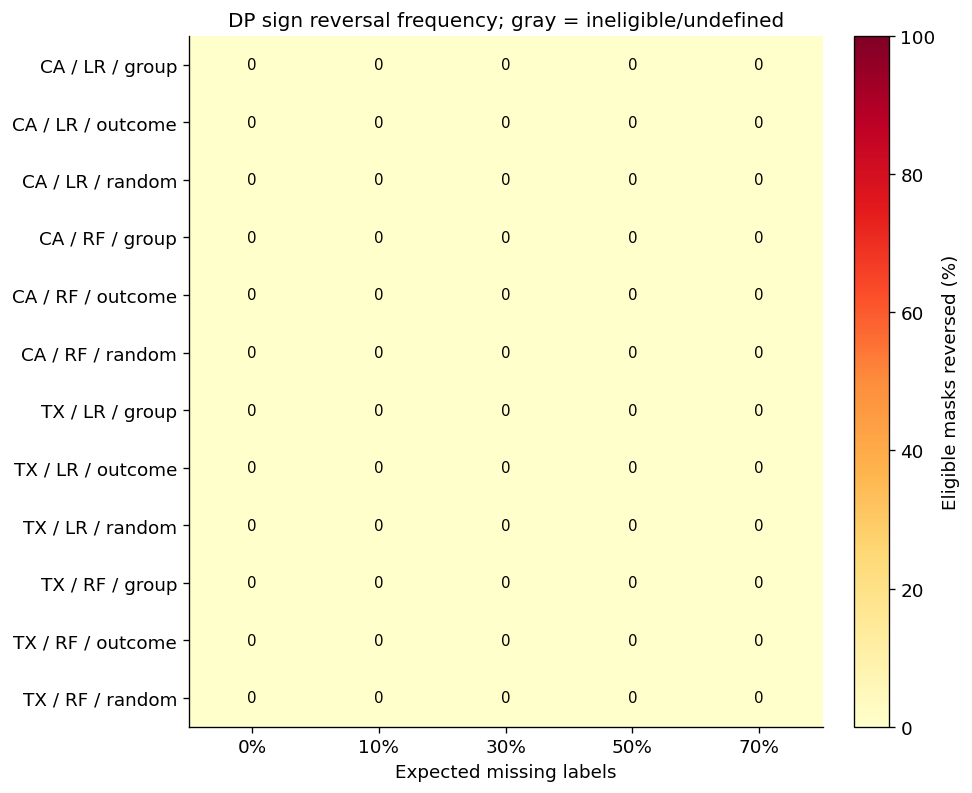

**RQ3 F6. Reversal map; eligibility requires |complete reference gap| ≥1 pp. Zero observed events do not prove zero risk.**

**RQ3 T5. Magnitude event proportions and valid mask denominators at 50% missingness.**

state,model,mechanism,metric,under_rate,over_rate,within_rate,valid_n
CA,LR,group,dp_gap,0.0200,0.0300,0.9500,100
CA,LR,group,eo_gap,0.0000,0.1600,0.8400,100
CA,LR,group,income_gap,0.0500,0.0300,0.9200,100
CA,LR,outcome,dp_gap,0.1500,0.0000,0.8500,100
CA,LR,outcome,eo_gap,0.0000,0.1500,0.8500,100
CA,LR,outcome,income_gap,0.5200,0.0000,0.4800,100
CA,LR,random,dp_gap,0.0200,0.0100,0.9700,100
CA,LR,random,eo_gap,0.0000,0.1000,0.9000,100
CA,LR,random,income_gap,0.0000,0.0200,0.9800,100
CA,RF,group,dp_gap,0.0300,0.0300,0.9400,100


**RQ3 T6. Reversal proportions, Monte Carlo SE and eligible denominators; NaN means ineligible/undefined.**

state,model,mechanism,metric,reversal_rate,reversal_mcse,reversal_eligible_n
CA,LR,group,dp_gap,0.0000,0.0000,100
CA,LR,group,eo_gap,undefined,undefined,0
CA,LR,group,income_gap,0.0000,0.0000,100
CA,LR,outcome,dp_gap,0.0000,0.0000,100
CA,LR,outcome,eo_gap,undefined,undefined,0
CA,LR,outcome,income_gap,0.0000,0.0000,100
CA,LR,random,dp_gap,0.0000,0.0000,100
CA,LR,random,eo_gap,undefined,undefined,0
CA,LR,random,income_gap,0.0000,0.0000,100
CA,RF,group,dp_gap,0.0000,0.0000,100


In [17]:
fig,axes=plt.subplots(1,3,figsize=(12,4),layout='constrained',sharey=True)
for ax,mechanism in zip(axes,MECHANISMS):
    g=subset(SUMMARY,state='CA',model='LR',metric='dp_gap',mechanism=mechanism).sort_values('rate')
    x=np.arange(len(g));bottom=np.zeros(len(g))
    for col,label,color in [('under_rate','Understated','#0072B2'),('within_rate','Within ±1 pp','#999999'),('over_rate','Overstated','#D55E00')]:
        values=100*g[col].to_numpy();ax.bar(x,values,bottom=bottom,label=label,color=color);bottom+=np.nan_to_num(values)
    ax.set_xticks(x,[f'{int(r*100)}' for r in g.rate]);decorate(ax,'Expected missing (%)',title=mechanism);ax.set_ylim(0,100)
axes[0].set_ylabel('Valid masks (%)');axes[1].legend(loc='upper center',bbox_to_anchor=(.5,-.2),ncol=3)
show_figure(fig,'RQ3_F5_magnitude_events','RQ3 F5. CA–LR DP magnitude classifications. All categories compare absolute disparity magnitudes with a ±1 pp tolerance.','RQ3')
s=subset(SUMMARY,metric='dp_gap').copy();s['condition']=s.state+' / '+s.model+' / '+s.mechanism
pivot=s.pivot(index='condition',columns='rate',values='reversal_rate')*100
fig,ax=plt.subplots(figsize=(8,6.5),layout='constrained')
arr=np.ma.masked_invalid(pivot.to_numpy());cmap=plt.get_cmap('YlOrRd').copy();cmap.set_bad('#D9D9D9')
im=ax.imshow(arr,cmap=cmap,vmin=0,vmax=100,aspect='auto');ax.set_yticks(range(len(pivot)),pivot.index);ax.set_xticks(range(len(pivot.columns)),[f'{int(r*100)}%' for r in pivot.columns]);ax.set_xlabel('Expected missing labels');ax.set_title('DP sign reversal frequency; gray = ineligible/undefined')
for i in range(len(pivot)):
    for j in range(len(pivot.columns)):
        v=pivot.iloc[i,j];ax.text(j,i,f'{v:.0f}' if np.isfinite(v) else 'NA',ha='center',va='center',fontsize=9,color='white' if np.isfinite(v) and v>55 else 'black')
fig.colorbar(im,ax=ax,label='Eligible masks reversed (%)')
show_figure(fig,'RQ3_F6_sign_reversal_map','RQ3 F6. Reversal map; eligibility requires |complete reference gap| ≥1 pp. Zero observed events do not prove zero risk.','RQ3')
t=subset(SUMMARY,rate=.5)[['state','model','mechanism','metric','under_rate','over_rate','within_rate','valid_n']]
show_table(t,'RQ3_T5_magnitude_event_rates','RQ3 T5. Magnitude event proportions and valid mask denominators at 50% missingness.','RQ3')
t=subset(SUMMARY,rate=.5)[['state','model','mechanism','metric','reversal_rate','reversal_mcse','reversal_eligible_n']]
show_table(t,'RQ3_T6_reversal_rates','RQ3 T6. Reversal proportions, Monte Carlo SE and eligible denominators; NaN means ineligible/undefined.','RQ3')

## Cell 13 — RQ4: paired classifier comparisons and predictive performance
**Research question:** How do audit effects differ across DP/EO and LR/RF?

**Outputs:** F7 compares paired absolute-error differences (RF minus LR) under the same masks at 50% missingness. Error bars give approximate 95% Monte Carlo intervals for the paired mean, not population confidence intervals. Negative values favor RF audit stability; positive values favor LR. F8 reports held-out accuracy/AUROC independently of audit reliability. T7 contains audit metric comparisons; T8 reports validation/test predictive performance. No best-model selection is made from these test results.

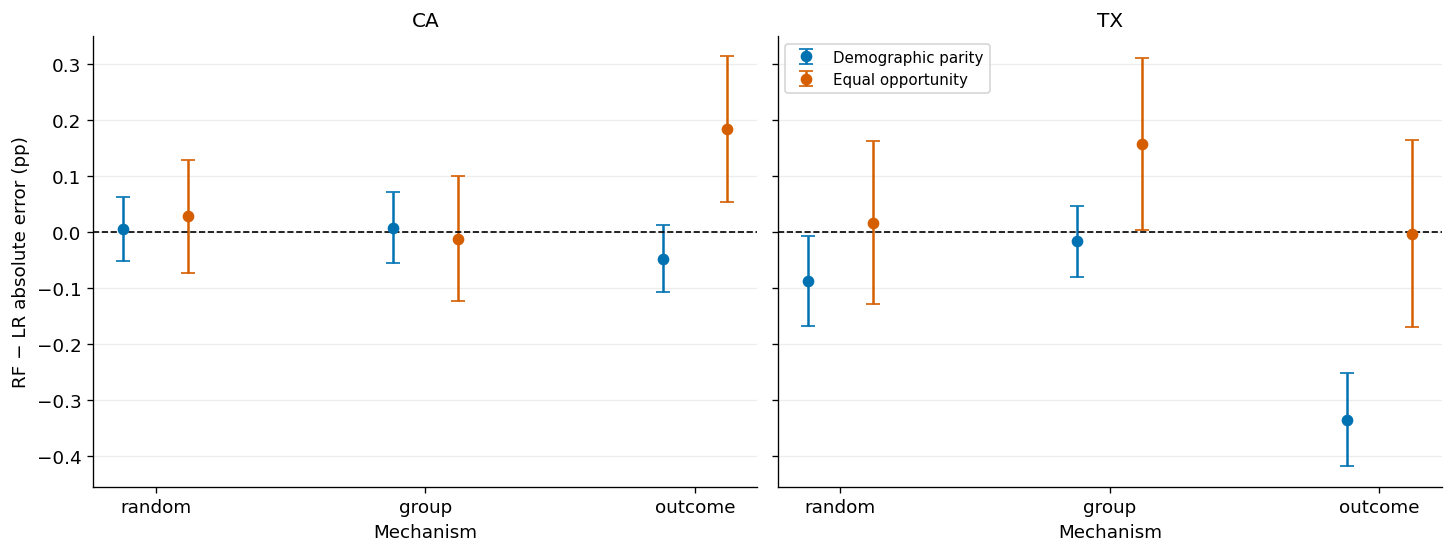

**RQ4 F7. Paired model differences at 50% missingness; intervals quantify Monte Carlo precision across masks.**

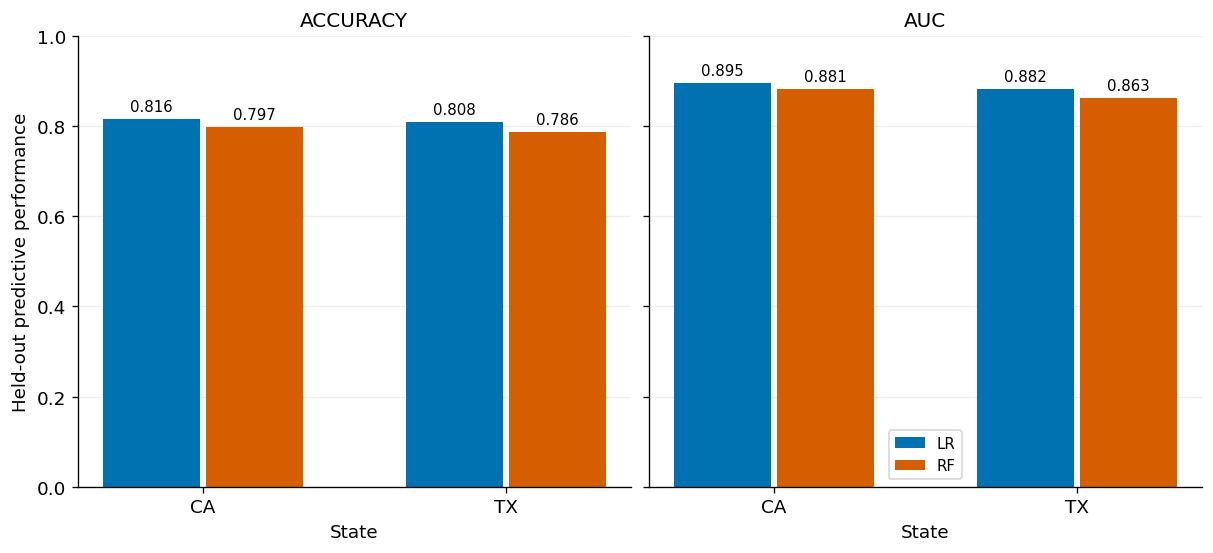

**RQ4 F8. Test-set accuracy and AUROC; these point estimates measure prediction performance, not audit reliability.**

**RQ4 T7. Audit performance by model and metric at 50% missingness; errors in pp.**

state,model,mechanism,metric,valid_n,mae_pp,mean_error_pp,mae_mcse_pp
CA,LR,group,dp_gap,100,0.4114,-0.0314,0.0290
CA,LR,group,eo_gap,100,0.6061,0.1870,0.0409
CA,LR,outcome,dp_gap,100,0.6109,-0.5488,0.0407
CA,LR,outcome,eo_gap,100,0.5741,-0.0331,0.0480
CA,LR,random,dp_gap,100,0.3703,0.0057,0.0273
CA,LR,random,eo_gap,100,0.5304,-0.0554,0.0430
CA,RF,group,dp_gap,100,0.4183,-0.0490,0.0324
CA,RF,group,eo_gap,100,0.5933,0.0509,0.0480
CA,RF,outcome,dp_gap,100,0.5621,-0.4136,0.0411
CA,RF,outcome,eo_gap,100,0.7572,0.0410,0.0590


**RQ4 T8. Validation and test accuracy/AUROC; no test-based tuning.**

state,model,split,n,accuracy,auc
CA,LR,validation,36585,0.8175,0.8960
CA,LR,test,36721,0.8164,0.8947
CA,RF,validation,36585,0.7983,0.8811
CA,RF,test,36721,0.7973,0.8814
TX,LR,validation,24838,0.8074,0.8842
TX,LR,test,24761,0.8082,0.8819
TX,RF,validation,24838,0.7841,0.8646
TX,RF,test,24761,0.7864,0.8629


In [18]:
paired=subset(RUNS,rate=.5)
paired=paired[paired.metric.isin(['dp_gap','eo_gap'])].pivot(index=['state','mechanism','metric','rep'],columns='model',values='abs_error').reset_index()
paired['difference']=paired.RF-paired.LR
paired_summary=paired.groupby(['state','mechanism','metric'],as_index=False).agg(mean=('difference','mean'),sd=('difference','std'),valid_n=('difference','count'))
paired_summary['mcse']=paired_summary.sd/np.sqrt(paired_summary.valid_n)
paired_summary.to_csv(OUT/'detailed/paired_model_difference.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout='constrained',sharey=True)
for ax,state in zip(axes,SOURCES):
    for offset,metric,color in [(-.12,'dp_gap','#0072B2'),(.12,'eo_gap','#D55E00')]:
        g=subset(paired_summary,state=state,metric=metric).set_index('mechanism').reindex(MECHANISMS)
        ax.errorbar(np.arange(3)+offset,100*g['mean'],yerr=196*g.mcse,fmt='o',capsize=4,label=LABEL[metric],color=color)
    ax.axhline(0,color='black',ls='--',lw=1);ax.set_xticks(range(3),MECHANISMS);decorate(ax,'Mechanism',title=state)
axes[0].set_ylabel('RF − LR absolute error (pp)');axes[1].legend()
show_figure(fig,'RQ4_F7_paired_model_effects','RQ4 F7. Paired model differences at 50% missingness; intervals quantify Monte Carlo precision across masks.','RQ4')
fig,axes=plt.subplots(1,2,figsize=(10,4.5),layout='constrained',sharey=True)
for ax,metric in zip(axes,['accuracy','auc']):
    for j,model in enumerate(['LR','RF']):
        g=subset(PERFORMANCE,split='test',model=model).set_index('state').reindex(list(SOURCES))
        bars=ax.bar(np.arange(2)+(j-.5)*.34,g[metric],width=.32,color=COLORS[model],label=model)
        ax.bar_label(bars,fmt='%.3f',fontsize=9,padding=3)
    ax.set_xticks(range(2),list(SOURCES));ax.set_ylim(0,1);decorate(ax,'State',title=metric.upper())
axes[0].set_ylabel('Held-out predictive performance');axes[1].legend()
show_figure(fig,'RQ4_F8_predictive_baselines','RQ4 F8. Test-set accuracy and AUROC; these point estimates measure prediction performance, not audit reliability.','RQ4')
t=subset(SUMMARY,rate=.5);t=t[t.metric.isin(['dp_gap','eo_gap'])][['state','model','mechanism','metric','mae','mean_error','mae_mcse','valid_n']]
show_table(pp_table(t,['mae','mean_error','mae_mcse']),'RQ4_T7_model_metric_audits','RQ4 T7. Audit performance by model and metric at 50% missingness; errors in pp.','RQ4')
show_table(PERFORMANCE,'RQ4_T8_predictive_metrics','RQ4 T8. Validation and test accuracy/AUROC; no test-based tuning.','RQ4')

## Cell 14 — RQ5: state comparisons, interval widths and observed support
**Research question:** How consistent are the patterns across states, and how does uncertainty change as observed support falls?

**Outputs:** F9 shows conditional bootstrap interval widths for LR by metric/mechanism/state as missingness grows. F10 relates EO interval width to the smaller group's observed positive count. T9 compares state/model audit errors and conditional interval widths at 50% missingness. T10 reports support and low-support flag frequencies across masks. Bootstrap widths use prespecified replicate 0; their apparent relationship with support is descriptive. Between-state differences are not causal state effects.

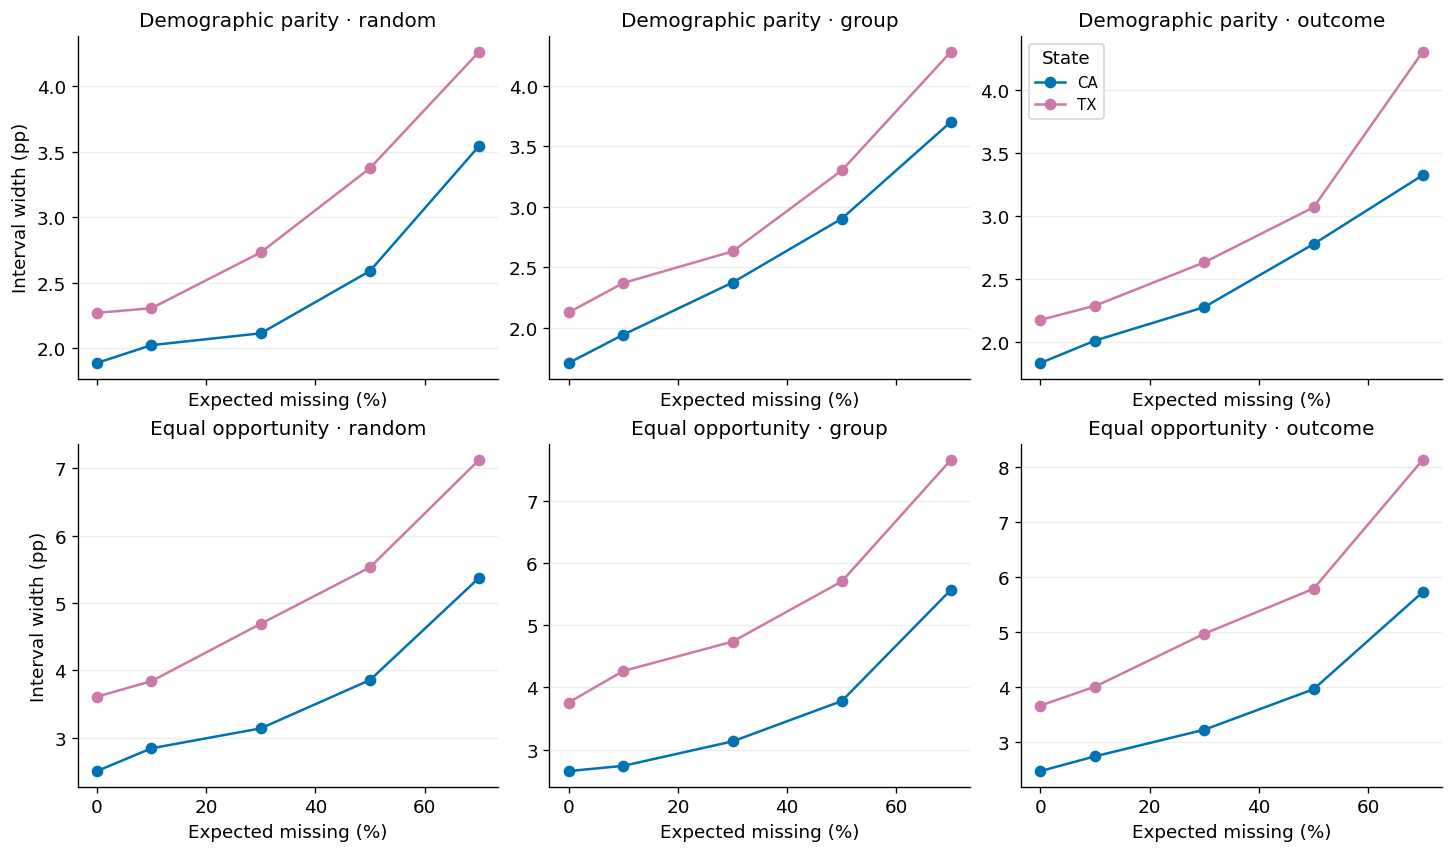

**RQ5 F9. LR household-bootstrap 95% percentile interval widths for mask replicate 0; no ACS population-coverage guarantee.**

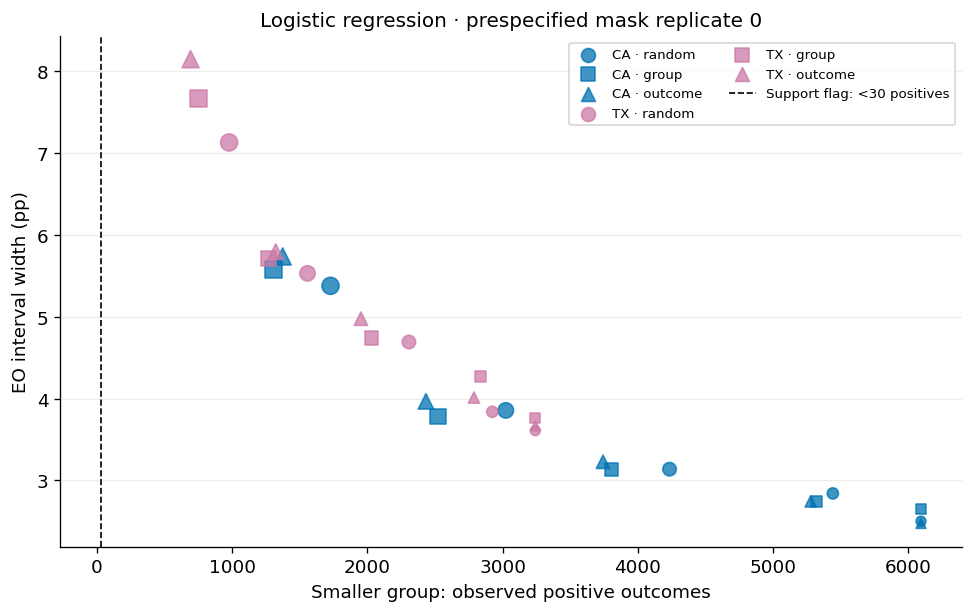

**RQ5 F10. Conditional EO interval width versus support; color=state, symbol=mechanism, size=missingness rate.**

**RQ5 T9. State comparisons at 50% missingness: mask-average errors and replicate-0 conditional interval widths (pp).**

state,model,mechanism,metric,valid_n,valid_boot,mae_pp,mean_error_pp,width_pp
CA,LR,group,dp_gap,100,500,0.4114,-0.0314,2.9022
CA,LR,group,eo_gap,100,500,0.6061,0.1870,3.7823
CA,LR,group,income_gap,100,500,0.4560,-0.0494,2.7383
CA,LR,outcome,dp_gap,100,500,0.6109,-0.5488,2.7765
CA,LR,outcome,eo_gap,100,500,0.5741,-0.0331,3.9653
CA,LR,outcome,income_gap,100,500,1.0033,-0.9951,2.7829
CA,LR,random,dp_gap,100,500,0.3703,0.0057,2.5915
CA,LR,random,eo_gap,100,500,0.5304,-0.0554,3.8554
CA,LR,random,income_gap,100,500,0.3598,0.0455,2.5681
CA,RF,group,dp_gap,100,500,0.4183,-0.0490,2.6474


**RQ5 T10. Support minima, mask counts and low-support proportions; thresholds are group n<100 or positives<30.**

state,mechanism,rate,mean_observed_n,minimum_group_n,minimum_positive_n,flagged_fraction,masks
CA,group,0.0000,36721.0000,17372,6095,0.0000,100
CA,group,0.1000,33045.4200,14970,5203,0.0000,100
CA,group,0.3000,25706.1200,10645,3734,0.0000,100
CA,group,0.5000,18355.0000,6905,2388,0.0000,100
CA,group,0.7000,11020.3900,3797,1276,0.0000,100
CA,outcome,0.0000,36721.0000,17372,6095,0.0000,100
CA,outcome,0.1000,33046.1600,15623,5184,0.0000,100
CA,outcome,0.3000,25697.2500,12188,3645,0.0000,100
CA,outcome,0.5000,18356.1500,8680,2341,0.0000,100
CA,outcome,0.7000,11014.3800,5173,1261,0.0000,100


In [19]:
fig,axes=plt.subplots(2,3,figsize=(12,7),layout='constrained',sharex=True)
for row,metric in enumerate(['dp_gap','eo_gap']):
    for col,mechanism in enumerate(MECHANISMS):
        ax=axes[row,col]
        for state in SOURCES:
            g=subset(CI,state=state,model='LR',metric=metric,mechanism=mechanism).sort_values('rate')
            ax.plot(100*g.rate,100*g.width,'o-',color=COLORS[state],label=state)
        decorate(ax,'Expected missing (%)', 'Interval width (pp)' if col==0 else None, LABEL[metric]+' · '+mechanism)
axes[0,2].legend(title='State')
show_figure(fig,'RQ5_F9_conditional_interval_widths','RQ5 F9. LR household-bootstrap 95% percentile interval widths for mask replicate 0; no ACS population-coverage guarantee.','RQ5')
fig,ax=plt.subplots(figsize=(8,5),layout='constrained')
markers={'random':'o','group':'s','outcome':'^'}
for state in SOURCES:
    for mechanism in MECHANISMS:
        g=subset(CI,state=state,model='LR',metric='eo_gap',mechanism=mechanism)
        support=np.minimum(g.positive_male,g.positive_female)
        ax.scatter(support,100*g.width,s=35+100*g.rate,color=COLORS[state],marker=markers[mechanism],alpha=.75,label=state+' · '+mechanism)
ax.axvline(30,color='black',lw=1,ls='--',label='Support flag: <30 positives')
decorate(ax,'Smaller group: observed positive outcomes','EO interval width (pp)','Logistic regression · prespecified mask replicate 0');ax.legend(fontsize=8,ncol=2)
show_figure(fig,'RQ5_F10_support_uncertainty','RQ5 F10. Conditional EO interval width versus support; color=state, symbol=mechanism, size=missingness rate.','RQ5')
t=subset(SUMMARY,rate=.5)[['state','model','mechanism','metric','mae','mean_error','valid_n']].merge(subset(CI,rate=.5)[['state','model','mechanism','metric','width','valid_boot']],on=['state','model','mechanism','metric'],validate='one_to_one')
show_table(pp_table(t,['mae','mean_error','width']),'RQ5_T9_state_comparison','RQ5 T9. State comparisons at 50% missingness: mask-average errors and replicate-0 conditional interval widths (pp).','RQ5')
# Compute the smaller-group and smaller-positive denominators without mixing groups.
support_copy=SUPPORT.copy();support_copy['smaller_n']=np.minimum(support_copy.n_male,support_copy.n_female);support_copy['smaller_positive_n']=np.minimum(support_copy.positive_male,support_copy.positive_female)
t=support_copy.groupby(['state','mechanism','rate'],as_index=False).agg(mean_observed_n=('observed_n','mean'),minimum_group_n=('smaller_n','min'),minimum_positive_n=('smaller_positive_n','min'),flagged_fraction=('low_support','mean'),masks=('rep','count'))
show_table(t,'RQ5_T10_support_flags','RQ5 T10. Support minima, mask counts and low-support proportions; thresholds are group n<100 or positives<30.','RQ5')

## Cell 15 — Artifact checks, interpretation notes and one results ZIP
**RQ coverage: RQ1–RQ5.** Verify that all five research questions have exactly two figure PDFs and two table CSVs, confirm zero-missingness control identities, and write an output index. Package **all** result/provenance files into a single ZIP outside the results directory, avoiding recursive ZIP inclusion. Checksums identify each included file. A download link appears only after successful ZIP validation.

Interpretation remains limited to selected 2018 analytical samples, simulated missingness and conditional fitted models. Sensitivities to odds ratios, prediction thresholds, split seeds and survey weighting require additional code and protocol review. No automatic text claims a significant or novel finding. Inspect valid counts, support flags and actual results before writing conclusions. The original proposal's dummy numbers are never used as measured evidence.

In [20]:
for rq in ['RQ1','RQ2','RQ3','RQ4','RQ5']:
    entries=[x for x in ARTIFACTS if x['rq']==rq]
    assert sum(x['kind']=='figure' for x in entries)==2, rq
    assert sum(x['kind']=='table' for x in entries)==2, rq
    assert all((OUT/x['file']).stat().st_size>0 for x in entries)
index=pd.DataFrame(ARTIFACTS)
index.to_csv(OUT/'artifact_index.csv',index=False)
(OUT/'README_results.txt').write_text(
    'AI RESPONSIBILITY — MEASURED EXPERIMENT OUTPUTS\n'
    + 'Authors: Dev Gupta and Tabassum Nadavinmani\nTarget journal: Machine Learning\n'
    + f'Run mode: {RUN_MODE}; mask repetitions: {REPS}; bootstrap repetitions: {BOOTS}\n'
    + ('SMOKE MODE: debugging evidence only, not final research results.\n' if RUN_MODE=='smoke' else 'Full mode: all eligible non-pilot sample rows.\n')
    + 'figures/: 10 scientific PDF figures. tables/: 10 RQ tables plus methods CSV tables.\n'
    + 'detailed/: audit runs, summaries, conditional intervals, paired differences, frozen predictions and split identifiers.\n'
    + 'provenance/: source proposal, pilot exclusions, config, environment and input hashes.\n'
    + 'artifact_index.csv: mapping from research question to output.\n'
    + 'Gaps/errors are proportions in detailed CSVs; columns ending _pp are percentage points. Rates/frequencies lie in [0,1].\n'
    + 'Undefined estimates remain NaN. Reversal requires |reference|>=0.01. Magnitude events use a +/-0.01 tolerance.\n'
    + 'Bootstrap intervals: conditional on model and first mask; not population coverage or ACS survey-design inference.\n'
    + 'Monte Carlo SE: simulation precision across masks, not sampling uncertainty.\n'
    + 'No causal discrimination, gender-identity representation, legal compliance or current population fairness conclusion is established.\n'
    + 'Null effects and support failures must be reported. Source-proposal dummy exhibits are planning examples only.\n'
    + 'Raw Census archives are excluded. Source identifiers are retained for traceability; publish only what reuse rules and project review permit.\n'
    + 'Executed notebook: save a Kaggle version to retain inline figures/tables. This ZIP contains the result files, not a copy of the live notebook state.\n')
checksums=[]
for path in sorted(OUT.rglob('*')):
    if path.is_file():
        checksums.append({'file':str(path.relative_to(OUT)),'bytes':path.stat().st_size,'sha256':hashlib.sha256(path.read_bytes()).hexdigest()})
pd.DataFrame(checksums).to_csv(OUT/'checksums.csv',index=False)
archive=Path(shutil.make_archive(str(OUT),'zip',root_dir=OUT.parent,base_dir=OUT.name))
with zipfile.ZipFile(archive) as z:
    assert z.testzip() is None
    assert len(z.namelist())>=len(checksums)
print('Verified 20 RQ exhibits plus methods/provenance outputs.')
print('Results ZIP:',archive,'| size:',round(archive.stat().st_size/1024**2,2),'MiB')
display(FileLink(str(archive)))

Verified 20 RQ exhibits plus methods/provenance outputs.
Results ZIP: /kaggle/working/AI_Responsibility_Results_full_20261109T102333894884Z.zip | size: 4.58 MiB


/kaggle/working/AI_Responsibility_Results_full_20261109T102333894884Z.zip

## Technical and scientific references
- Source proposal: **AI_Responsibility_Proposal_Dev_Tabassum.docx**, embedded and exported in `provenance/`.
- Target journal and anchor DOI: [Machine Learning / Dai et al. (2025)](https://doi.org/10.1007/s10994-025-06843-9).
- [Kaggle notebook documentation](https://www.kaggle.com/docs/notebooks).
- [GroupShuffleSplit documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html): split fractions refer to groups; row fractions are approximate.
- [OneHotEncoder documentation](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html): unseen categories are ignored at transform time.
- [Folktables benchmark and dataset documentation](https://github.com/socialfoundations/folktables).

**Before interpreting the outputs:** review leakage assertions, input hashes, model convergence, complete-label support, undefined estimates and the distinction between mask variability and conditional bootstrap uncertainty. Both team members should be able to explain these choices.